<a href="https://colab.research.google.com/github/kottuajaykumar007-del/VLM-Based-Product-Defect-Detection/blob/main/VLM_Product_Defect_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!wget -c -O /content/VisA_20220922.tar \
"https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar"


--2026-11-12 09:14:35--  https://amazon-visual-anomaly.s3.us-west-2.amazonaws.com/VisA_20220922.tar
Resolving amazon-visual-anomaly.s3.us-west-2.amazonaws.com (amazon-visual-anomaly.s3.us-west-2.amazonaws.com)... 3.5.78.50, 16.15.38.30, 16.15.41.17, ...
Connecting to amazon-visual-anomaly.s3.us-west-2.amazonaws.com (amazon-visual-anomaly.s3.us-west-2.amazonaws.com)|3.5.78.50|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1929840640 (1.8G) [application/x-tar]
Saving to: ‘/content/VisA_20220922.tar’

/content/VisA_20220 100%[===================>]   1.80G  2.81MB/s    in 6m 48s  

2026-11-12 09:21:24 (4.51 MB/s) - ‘/content/VisA_20220922.tar’ saved [1929840640/1929840640]



In [ ]:

import os
import tarfile

archive = "/content/VisA_20220922.tar"
extract_dir = "/content/VisA_dataset"

if os.path.exists(archive) and tarfile.is_tarfile(archive):
    print("Dataset archive verified. Extracting...")

    os.makedirs(extract_dir, exist_ok=True)

    with tarfile.open(archive, "r:*") as tar:
        tar.extractall(extract_dir)

    print("Extraction complete!")
    print(os.listdir(extract_dir)[:15])
else:
    print("Download incomplete or archive is invalid. Check the download cell.")


Dataset archive verified. Extracting...


/tmp/ipykernel_1387/2269836070.py:13: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(extract_dir)


Extraction complete!
['capsules', 'fryum', 'pcb1', 'chewinggum', 'macaroni1', 'pcb4', 'split_csv', 'LICENSE-DATASET', 'pcb2', 'pcb3', 'cashew', 'candle', 'pipe_fryum', 'macaroni2']


In [ ]:

import os
import tarfile

archive = "/content/VisA_20220922.tar"
extract_dir = "/content/VisA_dataset"

print("Checking dataset archive...")

if os.path.exists(archive) and tarfile.is_tarfile(archive):
    print("Archive verified!")
    print("Extracting dataset. Please wait...")

    os.makedirs(extract_dir, exist_ok=True)

    with tarfile.open(archive, "r:*") as tar:
        tar.extractall(path=extract_dir)

    print("\nExtraction completed!")
    print("Dataset folders:")

    for item in os.listdir(extract_dir)[:20]:
        print(item)
else:
    print("Archive missing or invalid. Check the download.")


Checking dataset archive...
Archive verified!
Extracting dataset. Please wait...


/tmp/ipykernel_1387/3138618907.py:16: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_dir)



Extraction completed!
Dataset folders:
capsules
fryum
pcb1
chewinggum
macaroni1
pcb4
split_csv
LICENSE-DATASET
pcb2
pcb3
cashew
candle
pipe_fryum
macaroni2


In [ ]:

import os

ROOT = "/content/VisA_dataset"

print("Checking dataset structure...\n")

for current_root, dirs, files in os.walk(ROOT):
    level = current_root.replace(ROOT, "").count(os.sep)

    # Display only the first 3 folder levels
    if level <= 2:
        indent = "  " * level
        print(f"{indent}{os.path.basename(current_root)}/")

        for filename in files[:5]:
            print(f"{indent}  {filename}")

    # Avoid listing the entire dataset
    if level >= 3:
        dirs[:] = []

print("\nStructure check completed.")


Checking dataset structure...

VisA_dataset/
  LICENSE-DATASET
  capsules/
    image_anno.csv
    Data/
  fryum/
    image_anno.csv
    Data/
  pcb1/
    image_anno.csv
    Data/
  chewinggum/
    image_anno.csv
    Data/
  macaroni1/
    image_anno.csv
    Data/
  pcb4/
    image_anno.csv
    Data/
  split_csv/
    2cls_fewshot.csv
    2cls_highshot.csv
    1cls.csv
  pcb2/
    image_anno.csv
    Data/
  pcb3/
    image_anno.csv
    Data/
  cashew/
    image_anno.csv
    Data/
  candle/
    image_anno.csv
    Data/
  pipe_fryum/
    image_anno.csv
    Data/
  macaroni2/
    image_anno.csv
    Data/

Structure check completed.


In [ ]:

import os
import pandas as pd
from IPython.display import display

ROOT = "/content/VisA_dataset"

csv_path = os.path.join(ROOT, "capsules", "image_anno.csv")

df = pd.read_csv(csv_path)

print("CSV columns:")
print(df.columns.tolist())

print("\nTotal annotated images:", len(df))

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset categories:")
print(os.listdir(ROOT))


CSV columns:
['image', 'label', 'mask']

Total annotated images: 702

First 5 rows:


,image,label,mask
0,capsules/Data/Images/Normal/000.JPG,normal,NaN
1,capsules/Data/Images/Normal/001.JPG,normal,NaN
2,capsules/Data/Images/Normal/002.JPG,normal,NaN
3,capsules/Data/Images/Normal/003.JPG,normal,NaN
4,capsules/Data/Images/Normal/004.JPG,normal,NaN



Dataset categories:
['capsules', 'fryum', 'pcb1', 'chewinggum', 'macaroni1', 'pcb4', 'split_csv', 'LICENSE-DATASET', 'pcb2', 'pcb3', 'cashew', 'candle', 'pipe_fryum', 'macaroni2']


In [ ]:

import os
import pandas as pd

ROOT = "/content/VisA_dataset"

all_data = []

for category in os.listdir(ROOT):
    csv_path = os.path.join(ROOT, category, "image_anno.csv")

    if os.path.isfile(csv_path):
        df = pd.read_csv(csv_path)
        df["category"] = category
        all_data.append(df)

visa_df = pd.concat(all_data, ignore_index=True)

print("Total annotated images:", len(visa_df))

print("\nLabels:")
print(visa_df["label"].value_counts(dropna=False))

print("\nLabels by category:")
print(pd.crosstab(visa_df["category"], visa_df["label"]))

# Verify image paths
def check_image(path):
    return os.path.isfile(os.path.join(ROOT, str(path)))

visa_df["image_exists"] = visa_df["image"].apply(check_image)

print("\nImage paths verified:")
print(visa_df["image_exists"].value_counts())

print("\nSample rows:")
display(visa_df.head())


Total annotated images: 10821

Labels:
label
normal                                                                                                                                      9621
melt                                                                                                                                         132
similar colour spot                                                                                                                           72
small scratches                                                                                                                               71
missing                                                                                                                                       69
                                                                                                                                            ... 
burnt,small scratches                                                                

,image,label,mask,category,image_exists
0,capsules/Data/Images/Normal/000.JPG,normal,NaN,capsules,True
1,capsules/Data/Images/Normal/001.JPG,normal,NaN,capsules,True
2,capsules/Data/Images/Normal/002.JPG,normal,NaN,capsules,True
3,capsules/Data/Images/Normal/003.JPG,normal,NaN,capsules,True
4,capsules/Data/Images/Normal/004.JPG,normal,NaN,capsules,True


Normal images: 9621
Defective images: 1200

NORMAL SAMPLE
Label: normal
Image path: /content/VisA_dataset/capsules/Data/Images/Normal/000.JPG


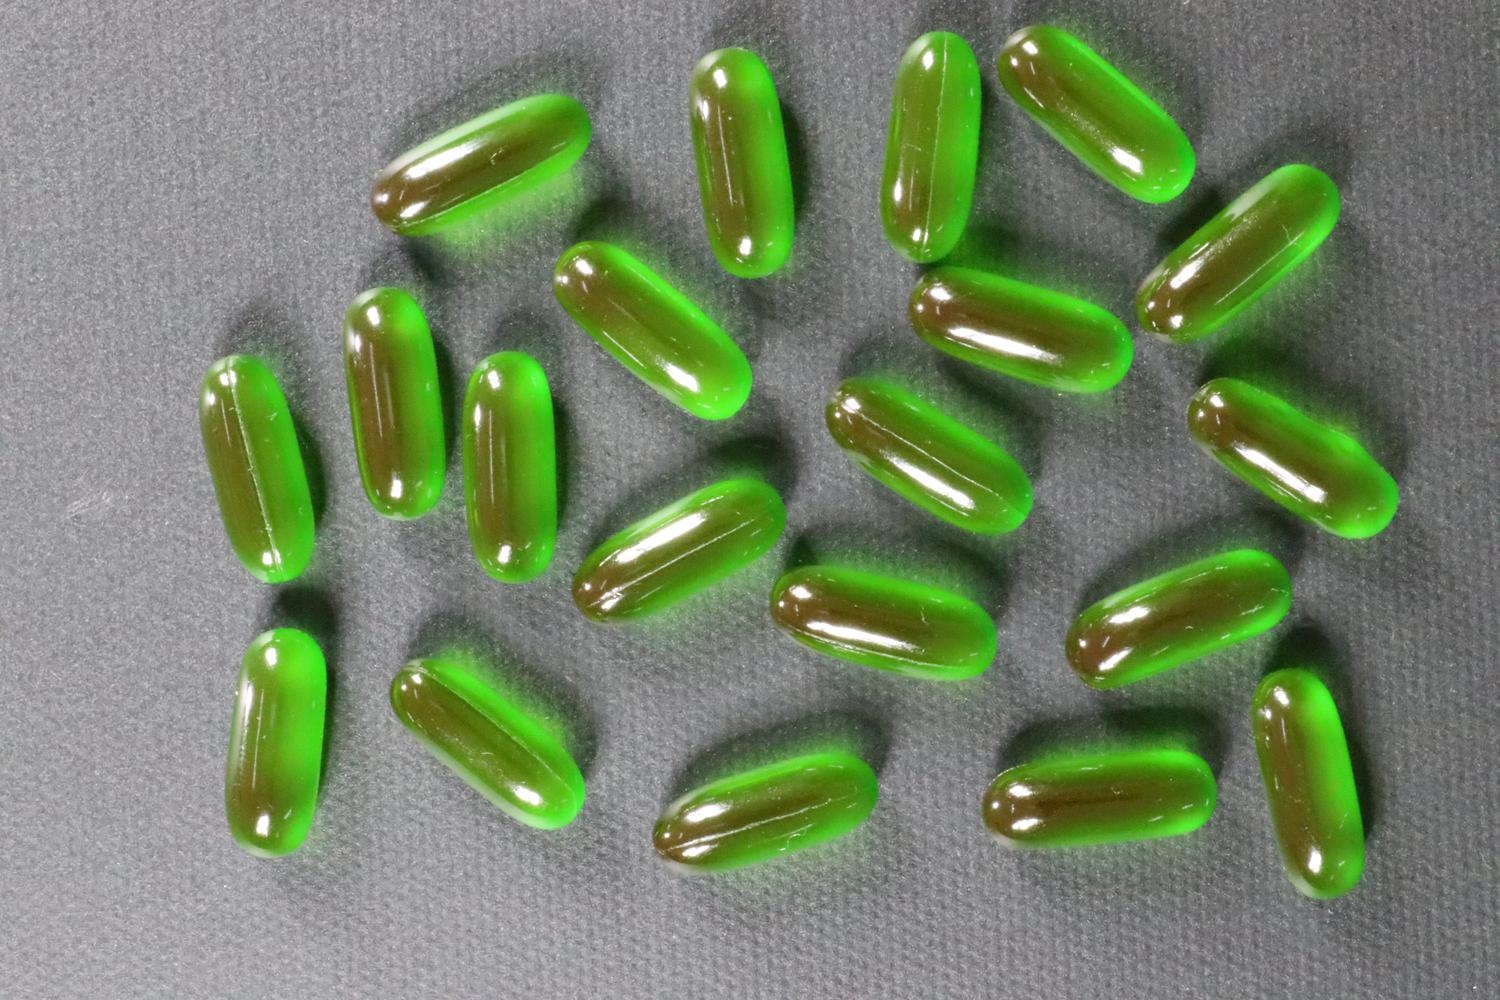

No defect mask for this sample.

DEFECTIVE SAMPLE
Label: bubble
Image path: /content/VisA_dataset/capsules/Data/Images/Anomaly/000.JPG


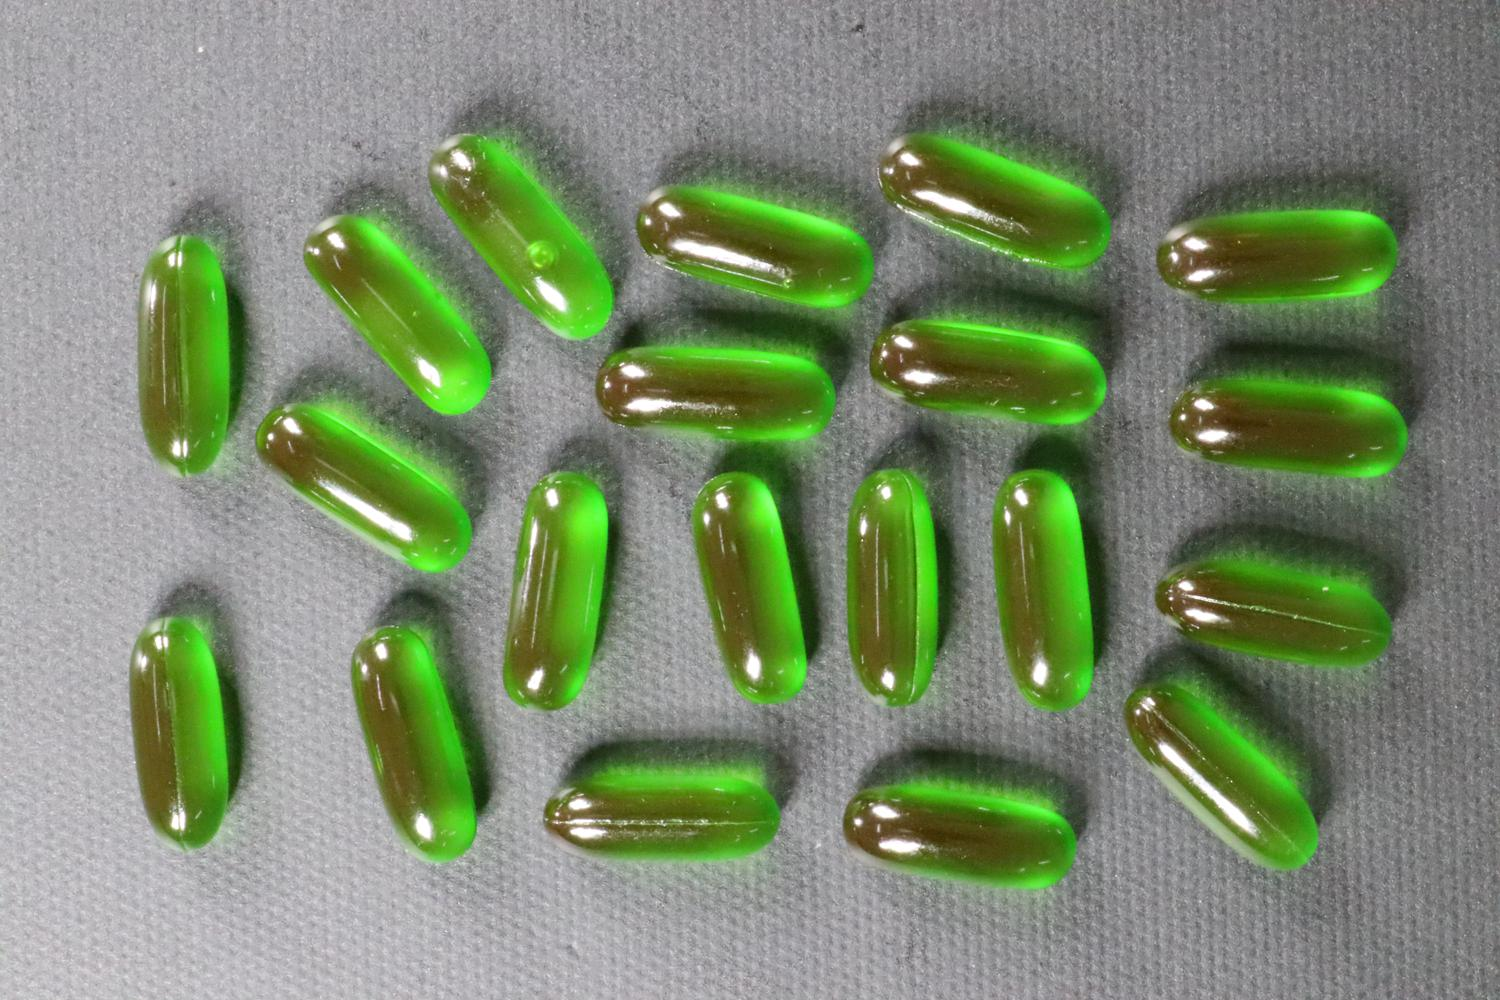

Mask path: /content/VisA_dataset/capsules/Data/Masks/Anomaly/000.png


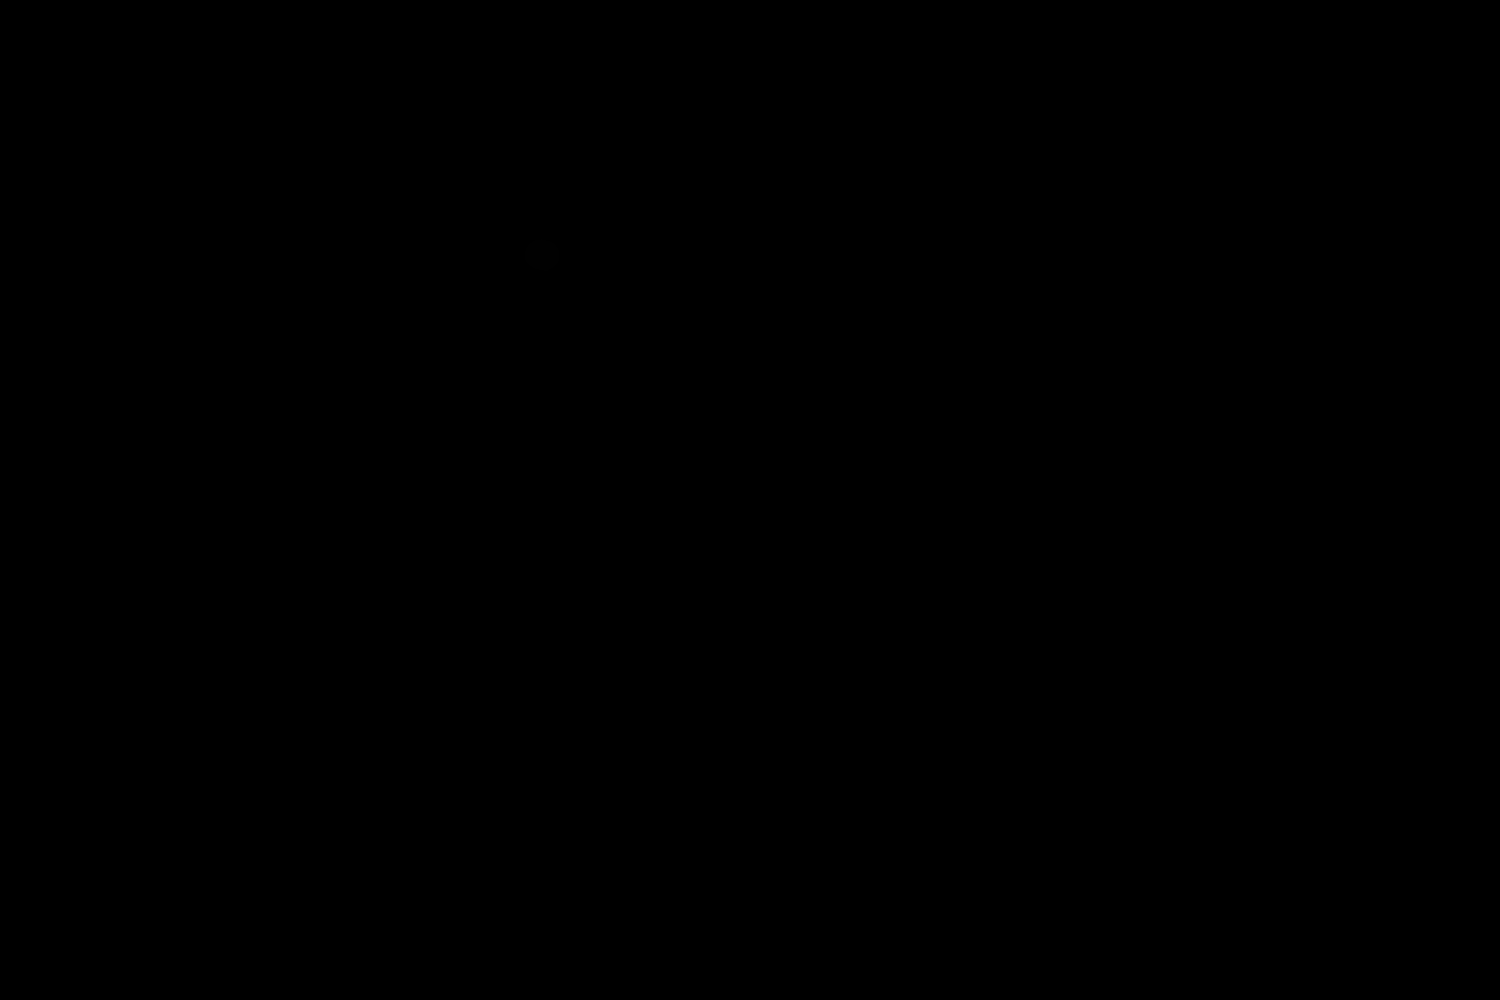

In [ ]:

import os
import pandas as pd
from PIL import Image
from IPython.display import display

ROOT = "/content/VisA_dataset"

# Select one normal image and one defective image
normal_rows = visa_df[visa_df["label"].str.lower() == "normal"]
defect_rows = visa_df[visa_df["label"].str.lower() != "normal"]

print("Normal images:", len(normal_rows))
print("Defective images:", len(defect_rows))

def show_sample(row, title):
    image_path = os.path.join(ROOT, str(row["image"]))
    print(f"\n{title}")
    print("Label:", row["label"])
    print("Image path:", image_path)

    if os.path.isfile(image_path):
        display(Image.open(image_path).convert("RGB"))
    else:
        print("Image file not found!")

    mask_value = row["mask"]

    if pd.notna(mask_value) and str(mask_value).strip():
        mask_path = os.path.join(ROOT, str(mask_value))
        print("Mask path:", mask_path)

        if os.path.isfile(mask_path):
            display(Image.open(mask_path))
        else:
            print("Mask file not found at this path.")
    else:
        print("No defect mask for this sample.")

if len(normal_rows):
    show_sample(normal_rows.iloc[0], "NORMAL SAMPLE")

if len(defect_rows):
    show_sample(defect_rows.iloc[0], "DEFECTIVE SAMPLE")


In [ ]:
%pip uninstall -y Pillow
%pip install --no-cache-dir Pillow

Found existing installation: pillow 12.3.0
Uninstalling pillow-12.3.0:
  Successfully uninstalled pillow-12.3.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 247.0 MB/s  0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [ ]:

!pip -q install -U transformers accelerate qwen-vl-utils

import torch
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor

MODEL_ID = "Qwen/Qwen2-VL-2B-Instruct"

processor = AutoProcessor.from_pretrained(MODEL_ID)

model = Qwen2VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype="auto",
    device_map="auto"
)

model.eval()

print("Qwen2-VL model loaded successfully!")


preprocessor_config.json:   0%|          | 0.00/347 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

... (3 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

Qwen2-VL model loaded successfully!


In [ ]:
import torch
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor

MODEL_ID = "Qwen/Qwen2-VL-2B-Instruct"

processor = AutoProcessor.from_pretrained(MODEL_ID)

model = Qwen2VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype="auto",
    device_map="auto"
)

model.eval()

print("Processor and model loaded successfully!")

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Processor and model loaded successfully!


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Vision AI model loaded successfully!


Saving Screenshot 2026-10-26 165511.png to Screenshot 2026-10-26 165511.png

Input image:


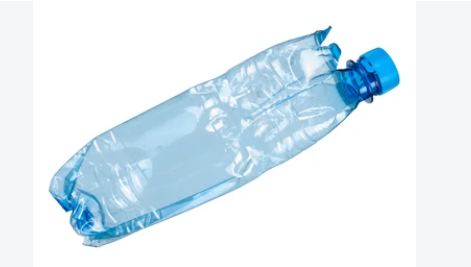


Analyzing image... Please wait.

       VISION AI INSPECTION REPORT
Image Description:
The image shows a plastic water bottle that appears to be crushed or damaged. The bottle is blue and has a blue cap. The bottle is lying on its side, and the top part of the bottle is bent and deformed.

Objects or Components Detected:
1. Plastic water bottle
2. Blue cap
3. Deformed top part of the bottle

Observable Condition:
The bottle is visibly damaged, with the top part being bent and deformed. The cap is intact.

Visible Defects or Unusual Features:
1. Deformed top part of the bottle
2. Bent top part of the bottle

Possible Concerns Based on Visible Evidence:
1. The bottle may be unusable for drinking water due to the damage.
2. The cap may be damaged or missing, making it difficult to open the bottle.

Suggested Next Steps, if Needed:
1. Check if the bottle can be used for drinking water.
2. Check if the cap is intact and functional.
3. If the bottle is unusable, consider disposing of it pro

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import torch
from PIL import Image
from google.colab import files
from transformers import (
    Qwen2VLForConditionalGeneration,
    AutoProcessor
)

# 1. Load the AI model
MODEL_ID = "Qwen/Qwen2-VL-2B-Instruct"

processor = AutoProcessor.from_pretrained(MODEL_ID)

model = Qwen2VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype="auto",
    device_map="auto"
)

model.eval()

print("Vision AI model loaded successfully!")

# 2. Upload input image
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload an image.")

filename = next(iter(uploaded))

# 3. Read the image
image = Image.open(filename).convert("RGB")

print("\nInput image:")
display(image)

# 4. Give instructions to AI
prompt = """
You are a Vision AI Inspection Assistant.

Analyze the uploaded image and generate a clear inspection report.

Include:
1. Image description
2. Objects or components detected
3. Observable condition
4. Visible defects or unusual features
5. Possible concerns based on visible evidence
6. Suggested next steps, if needed
7. Final inspection summary

Do not invent objects or defects.
Distinguish visible evidence from uncertain conclusions.
If no defect is clearly visible, state that explicitly.
Do not claim that hidden defects are absent.
"""

# 5. Prepare the image and prompt
messages = [
    {
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": image
            },
            {
                "type": "text",
                "text": prompt
            }
        ]
    }
]

prompt_text = processor.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

inputs = processor(
    text=[prompt_text],
    images=[image],
    padding=True,
    return_tensors="pt"
)

inputs = inputs.to(model.device)

# 6. Generate AI output
print("\nAnalyzing image... Please wait.")

with torch.inference_mode():
    output_ids = model.generate(
        **inputs,
        max_new_tokens=400
    )

# 7. Decode the response
generated_ids = output_ids[
    :, inputs.input_ids.shape[1]:
]

result = processor.batch_decode(
    generated_ids,
    skip_special_tokens=True
)[0]

# 8. Display the final report
print("\n" + "=" * 50)
print("       VISION AI INSPECTION REPORT")
print("=" * 50)
print(result)
print("=" * 50)

# 9. Save the report
report_filename = "vision_ai_inspection_report.txt"

with open(report_filename, "w", encoding="utf-8") as f:
    f.write("VISION AI INSPECTION REPORT\n\n")
    f.write(result)

print("\nReport saved:", report_filename)

# 10. Download the report
files.download(report_filename)

Saving Screenshot 2026-10-26 173036.png to Screenshot 2026-10-26 173036 (2).png


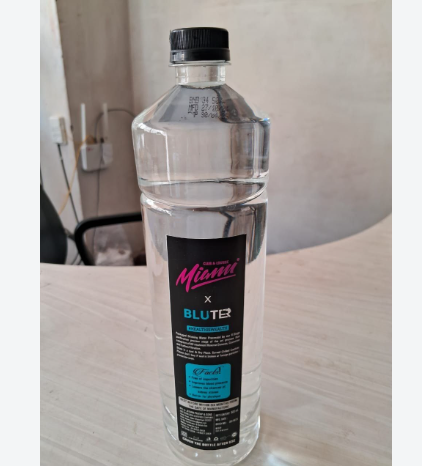


===== VISION AI INSPECTION REPORT =====
1. Product type: Miami x BLUTE
2. Defect status: DEFECT
3. Visible defect type: Uncertain
4. Approximate defect location: Label
5. Severity: High
6. Short explanation: Label is not clearly visible
7. Recommended inspection or corrective action: Inspect the label for any visible defects or missing information.


In [ ]:

from google.colab import files
from PIL import Image
from IPython.display import display
import torch

uploaded = files.upload()

for filename in uploaded:
    image = Image.open(filename).convert("RGB")
    display(image)

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {
                    "type": "text",
                    "text": """
Inspect this product image for visible defects.

Return:
1. Product type
2. Defect status: DEFECT, NO VISIBLE DEFECT, or UNCERTAIN
3. Visible defect type, if any
4. Approximate defect location
5. Severity: low, medium, high, or uncertain
6. Short explanation
7. Recommended inspection or corrective action

Do not invent defects. If the image is unclear, say uncertain.
Do not claim that a defect is absent merely because it is not visible.
"""
                }
            ]
        }
    ]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = processor(
        text=[prompt],
        images=[image],
        padding=True,
        return_tensors="pt"
    )

    inputs = inputs.to(model.device)

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=200
        )

    generated_ids = output_ids[:, inputs.input_ids.shape[1]:]

    result = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )[0]

    print("\n===== VISION AI INSPECTION REPORT =====")
    print(result)


Saving Screenshot 2026-10-26 173036.png to Screenshot 2026-10-26 173036 (3).png
AI raw response: ```json
{
  "status": "NO_VISIBLE_DEFECT",
  "defect_type": "none",
  "bbox": null,
  "location": "The product image does not contain any visible defects.",
  "severity": "low",
  "reason": "The image does not show any defects."
}
```

RESULT: NO VISIBLE DEFECT
No red circle drawn.


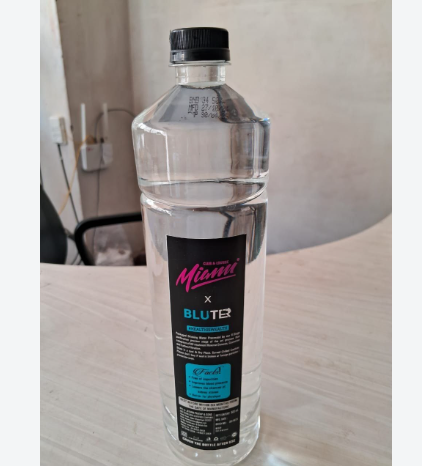


Explanation: The image does not show any defects.


In [ ]:

from google.colab import files
from PIL import Image, ImageDraw
from IPython.display import display
import torch
import json
import re

# Upload product image
uploaded = files.upload()

for filename in uploaded:
    image = Image.open(filename).convert("RGB")
    W, H = image.size

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": f"""
Inspect this product image for visible physical defects.

Return ONLY one valid JSON object with this exact schema:
{{
  "status": "DEFECT" or "NO_VISIBLE_DEFECT" or "UNCERTAIN",
  "defect_type": "short description",
  "bbox": [x1, y1, x2, y2] or null,
  "location": "short location description",
  "severity": "low, medium, high, or uncertain",
  "reason": "short explanation"
}}

Bounding box coordinates must be integers normalized from 0 to 1000:
x1,y1 = top-left; x2,y2 = bottom-right.
Box must enclose the visible defect, not the whole product.
If multiple defects exist, return the most obvious one.
If no visible defect exists, use status NO_VISIBLE_DEFECT and bbox null.
If uncertain, use status UNCERTAIN and bbox null.
Do not invent defects. Image dimensions are {W} by {H}.
"""}
        ]
    }]

    prompt = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = processor(
        text=[prompt], images=[image],
        padding=True, return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        output = model.generate(**inputs, max_new_tokens=180)

    generated = output[:, inputs.input_ids.shape[1]:]
    answer = processor.batch_decode(
        generated, skip_special_tokens=True
    )[0]

    print("AI raw response:", answer)

    # Parse the JSON response
    try:
        match = re.search(r"\{.*\}", answer, re.S)
        if not match:
            raise ValueError("JSON not found")
        result = json.loads(match.group())

        status = result.get("status", "UNCERTAIN").upper()
        bbox = result.get("bbox")

        annotated = image.copy()
        draw = ImageDraw.Draw(annotated)

        if status == "DEFECT" and isinstance(bbox, list) and len(bbox) == 4:
            x1, y1, x2, y2 = map(float, bbox)

            # Convert normalized coordinates to image pixels
            x1, x2 = x1 * W / 1000, x2 * W / 1000
            y1, y2 = y1 * H / 1000, y2 * H / 1000

            x1, x2 = sorted([max(0, min(W - 1, x1)),
                             max(0, min(W - 1, x2))])
            y1, y2 = sorted([max(0, min(H - 1, y1)),
                             max(0, min(H - 1, y2))])

            if x2 > x1 and y2 > y1:
                # Red ellipse around the predicted defect region
                pad = max(5, int(min(W, H) * 0.015))
                draw.ellipse(
                    [max(0, int(x1-pad)), max(0, int(y1-pad)),
                     min(W-1, int(x2+pad)), min(H-1, int(y2+pad))],
                    outline="red", width=max(3, W // 200)
                )
                print("\nRESULT: DEFECT DETECTED")
                print("Type:", result.get("defect_type"))
                print("Location:", result.get("location"))
                print("Severity:", result.get("severity"))
                display(annotated)
            else:
                print("\nRESULT: UNCERTAIN — invalid coordinates")
                display(image)

        elif status == "NO_VISIBLE_DEFECT":
            print("\nRESULT: NO VISIBLE DEFECT")
            print("No red circle drawn.")
            display(image)

        else:
            print("\nRESULT: UNCERTAIN — no reliable location returned")
            print("No red circle drawn.")
            display(image)

        print("\nExplanation:", result.get("reason", "Not provided"))

    except Exception as e:
        print("\nCould not validate AI response:", e)
        print("Showing original image without a circle.")
        display(image)


In [ ]:

# ==============================================================
# VISION AI — PRODUCT DEFECT INSPECTION DASHBOARD
# Qwen2-VL-2B-Instruct | Gradio | Google Colab
# Features: Classification, Localization, Verification,
#           Manual Review, Batch Inspection, CSV Report
# ==============================================================

!pip -q install -U gradio transformers accelerate pandas pillow

import os
import re
import json
import time
import tempfile
import traceback

import torch
import pandas as pd
import gradio as gr

from PIL import Image, ImageDraw
from transformers import (
    Qwen2VLForConditionalGeneration,
    AutoProcessor
)

# ---------------- 1. LOAD MODEL ----------------

MODEL_ID = "Qwen/Qwen2-VL-2B-Instruct"

print("Loading VISION AI model...")
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    model_dtype = torch.float16
else:
    model_dtype = torch.float32

processor = AutoProcessor.from_pretrained(MODEL_ID)

model = Qwen2VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=model_dtype,
    device_map="auto"
)

model.eval()

print("Model loaded successfully!")
print("Model device:", model.device)


# ---------------- 2. HELPER FUNCTIONS ----------------

def run_vlm(image, prompt, max_new_tokens=250):
    """Run inference with the already-loaded Qwen2-VL model."""

    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": prompt}
        ]
    }]

    formatted_prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = processor(
        text=[formatted_prompt],
        images=[image],
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.inference_mode():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    generated_ids = output_ids[
        :, inputs.input_ids.shape[1]:
    ]

    result = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )[0]

    return result.strip()


def parse_json(text):
    """Extract JSON safely; return None if parsing fails."""

    if not text:
        return None

    try:
        match = re.search(r"\{.*\}", text, re.S)
        if match:
            return json.loads(match.group(0))
    except (json.JSONDecodeError, TypeError):
        pass

    return None


def safe_status(data, key="status"):
    """Accept only known inspection labels."""

    if not data:
        return "UNCERTAIN"

    value = str(data.get(key, "UNCERTAIN")).strip().upper()

    allowed = {
        "DEFECT",
        "NO VISIBLE DEFECT",
        "UNCERTAIN"
    }

    return value if value in allowed else "UNCERTAIN"


def format_report(data, raw):
    if data is not None:
        return json.dumps(data, indent=2, ensure_ascii=False)
    return "Could not parse structured JSON. Raw model response:\n\n" + raw


# ---------------- 3. DEFECT CLASSIFICATION ----------------

CLASSIFICATION_PROMPT = """
You are an assistant for visual product quality inspection.

Inspect only evidence visible in the image.

Return valid JSON only:
{
  "product_type": "product type or unknown",
  "status": "DEFECT | NO VISIBLE DEFECT | UNCERTAIN",
  "defect_type": "visible defect or none observed",
  "visual_evidence": "specific visible evidence",
  "severity": "LOW | MEDIUM | HIGH | UNCERTAIN",
  "location_description": "approximate location or unknown",
  "recommended_action": "reasonable next inspection or corrective action",
  "limitations": "what cannot be concluded from this image"
}

Rules:
- Never invent a defect, measurement, or hidden damage.
- Do not claim a product is guaranteed defect-free.
- If evidence is unclear, use UNCERTAIN.
- Severity is a visual estimate, not an engineering certification.
- Recommendations must not claim a repair has been performed.
- Return JSON only.
"""


def classify_image(image):
    raw = run_vlm(image, CLASSIFICATION_PROMPT)
    data = parse_json(raw)

    if data is None:
        data = {
            "status": "UNCERTAIN",
            "visual_evidence": "Unable to parse structured model output.",
            "raw_model_response": raw
        }

    data["status"] = safe_status(data)
    return data, raw


# ---------------- 4. MAIN INSPECTION ----------------

def analyze_product(image):
    if image is None:
        raise gr.Error("Please upload a product image first.")

    start = time.time()

    try:
        data, raw = classify_image(image)

        status = data["status"]

        if status == "DEFECT":
            decision = "POTENTIAL DEFECT — REVIEW REQUIRED"
        elif status == "NO VISIBLE DEFECT":
            decision = "NO VISIBLE DEFECT OBSERVED — NOT A GUARANTEE"
        else:
            decision = "UNCERTAIN — MANUAL REVIEW REQUIRED"

        report = format_report(data, raw)
        elapsed = round(time.time() - start, 2)

        return decision, report, f"{elapsed} seconds"

    except Exception as e:
        raise gr.Error(f"Inspection failed: {str(e)}")


# ---------------- 5. SMART DEFECT LOCALIZATION ----------------

LOCALIZATION_PROMPT = """
Inspect this product image for a clearly visible physical defect.

Return valid JSON only:
{
  "status": "DEFECT | NO VISIBLE DEFECT | UNCERTAIN",
  "defect_type": "description or unknown",
  "bbox": [x1, y1, x2, y2],
  "location_description": "plain-language location",
  "visual_evidence": "visible evidence"
}

If you cannot identify a specific visible defect, set bbox to null.
Coordinates must be normalized from 0 to 1000:
[x1, y1, x2, y2], with x1 < x2 and y1 < y2.
Coordinates should enclose the suspected defect, not the whole product.
Do not invent coordinates. Use UNCERTAIN if evidence is insufficient.
A predicted box is only an estimate, not verified ground truth.
Return JSON only.
"""


def smart_localization(image):
    if image is None:
        raise gr.Error("Upload an image first.")

    raw = run_vlm(image, LOCALIZATION_PROMPT)
    data = parse_json(raw)

    annotated = image.copy()
    note = (
        "No valid bounding box was returned. "
        "No defect location has been marked."
    )

    if data:
        box_values = data.get("bbox")

        if isinstance(box_values, list) and len(box_values) == 4:
            try:
                coords = [float(v) for v in box_values]

                x1, y1, x2, y2 = coords

                valid = (
                    all(0 <= v <= 1000 for v in coords)
                    and x1 < x2
                    and y1 < y2
                )

                if valid:
                    width, height = annotated.size

                    pixel_box = (
                        int(x1 * width / 1000),
                        int(y1 * height / 1000),
                        int(x2 * width / 1000),
                        int(y2 * height / 1000)
                    )

                    draw = ImageDraw.Draw(annotated)
                    line_width = max(3, min(width, height) // 150)

                    draw.rectangle(
                        pixel_box,
                        outline="red",
                        width=line_width
                    )

                    note = (
                        "RED BOX = MODEL-ESTIMATED REGION. "
                        "Verify visually; localization accuracy "
                        "has not been established."
                    )

            except (TypeError, ValueError, OverflowError):
                note = "Invalid coordinates. No box was drawn."

    report = format_report(data, raw)
    return annotated, note, report


# ---------------- 6. TWO-STAGE VERIFICATION ----------------

SECOND_PASS_PROMPT = """
Review this product image independently for visible defects.

Return valid JSON only:
{
  "review_status": "DEFECT | NO VISIBLE DEFECT | UNCERTAIN",
  "visual_evidence": "specific visible evidence",
  "possible_false_alarm": "could this be normal product appearance?",
  "limitations": "what cannot be concluded"
}

Do not invent defects.
Use UNCERTAIN if evidence is insufficient.
Do not assume a defect exists because one was previously suspected.
Return JSON only.
"""


def two_stage_verification(image):
    if image is None:
        raise gr.Error("Upload an image first.")

    first_data, first_raw = classify_image(image)

    second_raw = run_vlm(image, SECOND_PASS_PROMPT)
    second_data = parse_json(second_raw)

    first_status = safe_status(first_data, "status")
    second_status = safe_status(second_data, "review_status")

    if (
        first_status == second_status
        and first_status != "UNCERTAIN"
    ):
        decision = (
            f"{first_status} — BOTH PASSES AGREE; "
            "HUMAN REVIEW STILL RECOMMENDED"
        )
    else:
        decision = (
            "MANUAL REVIEW REQUIRED — PASSES DISAGREE "
            "OR EVIDENCE IS UNCERTAIN"
        )

    report = {
        "first_pass": first_data,
        "second_pass": (
            second_data if second_data else second_raw
        ),
        "decision": decision,
        "important_limitation": (
            "Both passes use the same Qwen2-VL model. "
            "Agreement is not independent verification and "
            "does not prove correctness."
        )
    }

    return decision, json.dumps(
        report, indent=2, ensure_ascii=False
    )


# ---------------- 7. UNCERTAINTY & MANUAL REVIEW ----------------

def confidence_and_review(image):
    if image is None:
        raise gr.Error("Upload an image first.")

    data, raw = classify_image(image)
    status = safe_status(data)

    evidence = str(data.get("visual_evidence", "")).strip()

    weak_evidence = (
        not evidence
        or "insufficient" in evidence.lower()
        or "unclear" in evidence.lower()
        or "unknown" in evidence.lower()
    )

    if status == "UNCERTAIN" or weak_evidence:
        action = "MANUAL REVIEW REQUIRED"
    else:
        action = "AI SUGGESTION — HUMAN CHECK RECOMMENDED"

    report = {
        "model_status": status,
        "review_action": action,
        "visual_evidence": evidence or "No usable evidence provided",
        "severity": data.get("severity", "UNCERTAIN"),
        "limitations": data.get("limitations", "Not specified"),
        "confidence_note": (
            "No calibrated confidence percentage is available. "
            "The model's text output is not a calibrated probability."
        ),
        "model_output": data if data else raw
    }

    return action, json.dumps(
        report, indent=2, ensure_ascii=False
    )


# ---------------- 8. BATCH INSPECTION & CSV REPORT ----------------

def batch_inspection(files):
    if not files:
        raise gr.Error("Upload one or more images first.")

    rows = []

    for path in files:
        filename = os.path.basename(path)

        try:
            with Image.open(path) as source:
                image = source.convert("RGB")

            data, raw = classify_image(image)

            rows.append({
                "image": filename,
                "product_type": data.get("product_type", "Unknown"),
                "status": safe_status(data),
                "defect_type": data.get("defect_type", "Unknown"),
                "severity": data.get("severity", "UNCERTAIN"),
                "location": data.get("location_description", "Unknown"),
                "evidence": data.get("visual_evidence", ""),
                "recommended_action": data.get(
                    "recommended_action", ""
                ),
                "review_note": (
                    "AI-assisted result; human verification recommended"
                )
            })

        except Exception as e:
            rows.append({
                "image": filename,
                "product_type": "ERROR",
                "status": "UNCERTAIN",
                "defect_type": str(e)[:250],
                "severity": "UNCERTAIN",
                "location": "Unknown",
                "evidence": "Inspection failed",
                "recommended_action": "Retry inspection",
                "review_note": "Processing error"
            })

    df = pd.DataFrame(rows)

    report_path = os.path.join(
        tempfile.gettempdir(),
        "vision_ai_inspection_report.csv"
    )

    df.to_csv(report_path, index=False)

    return df, report_path


# ---------------- 9. GRADIO WEBSITE ----------------

with gr.Blocks(
    theme=gr.themes.Soft(),
    title="VISION AI — Product Inspection"
) as app:

    gr.Markdown("""
    # 🔍 VISION AI — PRODUCT DEFECT INSPECTION
    ### INDUSTRIAL AI • QUALITY INTELLIGENCE

    Upload a product image for AI-assisted visual inspection.

    **Important:** Results are advisory. This system has not been
    certified for industrial quality control. Validate predictions
    against labelled test data before relying on them.
    """)

    with gr.Tab("Main Inspection"):

        with gr.Row():
            with gr.Column():
                image_input = gr.Image(
                    type="pil",
                    label="Upload Product Image"
                )

                analyze_btn = gr.Button(
                    "ANALYZE PRODUCT",
                    variant="primary"
                )

            with gr.Column():
                decision_output = gr.Textbox(
                    label="Inspection Decision"
                )

                time_output = gr.Textbox(
                    label="Processing Time"
                )

                report_output = gr.Textbox(
                    label="Inspection Report",
                    lines=14
                )

        analyze_btn.click(
            fn=analyze_product,
            inputs=image_input,
            outputs=[
                decision_output,
                report_output,
                time_output
            ]
        )

    with gr.Tab("1. Smart Defect Localization"):

        gr.Markdown(
            "The red box is an AI-estimated region, not guaranteed "
            "ground truth. Verify it against the original image."
        )

        localize_btn = gr.Button(
            "FIND SUSPECTED DEFECT REGION",
            variant="primary"
        )

        localized_image = gr.Image(
            label="Annotated Image"
        )

        localization_note = gr.Textbox(
            label="Localization Status"
        )

        localization_report = gr.Textbox(
            label="Localization Details",
            lines=10
        )

        localize_btn.click(
            fn=smart_localization,
            inputs=image_input,
            outputs=[
                localized_image,
                localization_note,
                localization_report
            ]
        )

    with gr.Tab("2. Two-Stage Verification"):

        gr.Markdown(
            "Two separate prompts are used with the same model. "
            "This is a second-pass review, not independent verification."
        )

        verify_btn = gr.Button(
            "RUN TWO-STAGE REVIEW",
            variant="primary"
        )

        verify_decision = gr.Textbox(
            label="Review Decision"
        )

        verify_report = gr.Textbox(
            label="Two-Pass Results",
            lines=14
        )

        verify_btn.click(
            fn=two_stage_verification,
            inputs=image_input,
            outputs=[
                verify_decision,
                verify_report
            ]
        )

    with gr.Tab("3. Confidence & Manual Review"):

        gr.Markdown(
            "No unvalidated percentage is displayed. Ambiguous cases "
            "are flagged for manual review."
        )

        review_btn = gr.Button(
            "ASSESS UNCERTAINTY",
            variant="primary"
        )

        review_decision = gr.Textbox(
            label="Review Action"
        )

        review_report = gr.Textbox(
            label="Evidence and Limitations",
            lines=14
        )

        review_btn.click(
            fn=confidence_and_review,
            inputs=image_input,
            outputs=[
                review_decision,
                review_report
            ]
        )

    with gr.Tab("4. Batch Inspection & Reports"):

        gr.Markdown(
            "Upload multiple product images. Each result is an "
            "AI-generated suggestion and should be checked."
        )

        batch_files = gr.File(
            label="Select Product Images",
            file_count="multiple",
            file_types=["image"],
            type="filepath"
        )

        batch_btn = gr.Button(
            "INSPECT ALL IMAGES",
            variant="primary"
        )

        batch_table = gr.Dataframe(
            label="Batch Inspection Results"
        )

        csv_file = gr.File(
            label="Download CSV Inspection Report"
        )

        batch_btn.click(
            fn=batch_inspection,
            inputs=batch_files,
            outputs=[
                batch_table,
                csv_file
            ]
        )

    gr.Markdown("""
    ---
    **VISION AI | Research Prototype**

    A visible defect may be missed, and an apparent defect may be
    a normal product feature. Use labelled validation data and
    qualified human inspection for real-world deployment.
    """)


# ---------------- 10. LAUNCH WEBSITE ----------------

app.queue()

app.launch(
    share=True,
    debug=True
)


Loading VISION AI model...
GPU available: True


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Model loaded successfully!
Model device: cuda:0


/tmp/ipykernel_1387/2226781708.py:459: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://555c692fb8c5bc1e0b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

# STEP 4: REGISTER QWEN2-VL WITH EXTENDABLE AI

def qwen_inspect_image(image):
    """
    Connect Qwen2-VL to the Extendable AI manager.
    This function accepts an image and returns the model's response.
    """
    from qwen_vl_utils import process_vision_info

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": image},
                {
                    "type": "text",
                    "text": (
                        "Inspect this product image for visible defects. "
                        "State whether a defect is visible, its type, "
                        "location, severity, and recommended action. "
                        "If uncertain, clearly say so. Do not invent defects."
                    )
                }
            ]
        }
    ]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(messages)

    inputs = processor(
        text=[prompt],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    )

    inputs = inputs.to(model.device)

    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=200
        )

    generated_ids = [
        output[len(input_ids):]
        for input_ids, output in zip(inputs.input_ids, output_ids)
    ]

    return processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )[0]


# Create manager if it doesn't exist
if "ai_manager" not in globals():
    ai_manager = ExtendableAI()

# Register the current model
ai_manager.register_model(
    "Qwen2-VL-2B-Instruct",
    qwen_inspect_image
)

print("Available AI models:", ai_manager.available_models())
